# Lab 3: Nim with Minimax and Alpha-Beta, plus a full EDA of the game data
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**.

**Game (Nim):** piles of stones; players A (MAX) and B (MIN) take turns; each turn you take 1 or more stones from ONE pile; whoever takes the last stone wins. Value: +1 A wins, -1 B wins.

**Part 1 (cells 1 to 4):** the game and the search. **Part 2 (cells 5 to 8):** Step 3 on real data: build a table of games, check quality, describe it, ask questions, plot, interpret.

## Cell 1: The game

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START = (3, 4, 5)            # stones in each pile: the board of the game (Nim)
nodes = 0                    # how many positions the search looks at

def moves(piles, order="small_first"):
    """All positions we can reach by taking some stones from ONE pile."""
    result = []
    for i, n in enumerate(piles):
        takes = range(1, n + 1) if order == "small_first" else range(n, 0, -1)
        for take in takes:
            new = list(piles)
            new[i] = n - take
            result.append(tuple(new))
    return result

print(moves((1, 2)))

[(0, 2), (1, 1), (1, 0)]


## Cell 2: Minimax

In [4]:
def minimax(piles, player):
    """+1 if player A wins, -1 if player B wins (both play perfectly)."""
    global nodes
    nodes += 1
    if sum(piles) == 0:                     # the previous player took the last stone and won
        return -1 if player == "A" else 1
    values = [minimax(nxt, "B" if player == "A" else "A") for nxt in moves(piles)]
    return max(values) if player == "A" else min(values)

## Cell 3: Alpha-beta pruning

In [5]:
def alphabeta(piles, player, alpha, beta, order):
    global nodes
    nodes += 1
    if sum(piles) == 0:
        return -1 if player == "A" else 1
    if player == "A":
        value = -2
        for nxt in moves(piles, order):
            value = max(value, alphabeta(nxt, "B", alpha, beta, order))
            alpha = max(alpha, value)
            if alpha >= beta:
                break                      # prune: B will never allow this branch
        return value
    value = 2
    for nxt in moves(piles, order):
        value = min(value, alphabeta(nxt, "A", alpha, beta, order))
        beta = min(beta, value)
        if alpha >= beta:
            break                          # prune: A already has a better option
    return value

## Cell 4: Count the nodes

In [6]:
nodes = 0
v1 = minimax(START, "A")
n_minimax = nodes

nodes = 0
v2 = alphabeta(START, "A", -2, 2, "small_first")
n_ab = nodes

nodes = 0
v3 = alphabeta(START, "A", -2, 2, "big_first")
n_good = nodes

print("value of START (+1 = A wins):", v1, v2, v3)
print("minimax nodes:           ", n_minimax)
print("alpha-beta (natural):    ", n_ab)
print("alpha-beta (big first):  ", n_good)

value of START (+1 = A wins): 1 1 1
minimax nodes:            1038768
alpha-beta (natural):     33916
alpha-beta (big first):   4332


## Cell 5: Build the data table (200 games) and save it as CSV

In [11]:
def best_move(piles, player):
    best_nxt, best_value = None, None
    for nxt in moves(piles, "big_first"):
        value = alphabeta(nxt, "B" if player == "A" else "A", -2, 2, "big_first")
        better = best_value is None or (value > best_value if player == "A" else value < best_value)
        if better:
            best_nxt, best_value = nxt, value
    return best_nxt

rng = np.random.default_rng(0)
rows = []
for game in range(200):
    piles = tuple(int(x) for x in rng.integers(1, 5, size=3))     # random start: 3 piles of 1..4 stones
    nodes = 0
    start_value = alphabeta(piles, "A", -2, 2, "big_first")
    nodes_ab = nodes
    nodes = 0
    minimax(piles, "A")
    nodes_mm = nodes
    board, player, n_moves = piles, "A", 0            # play: A is smart, B plays at random
    while sum(board) > 0:
        if player == "A":
            board = best_move(board, "A")
        else:
            board = best_move(board, "B") # play: both A and B use optimal moves
        player = "B" if player == "A" else "A"
        n_moves += 1
    rows.append({"p1": piles[0], "p2": piles[1], "p3": piles[2], "total": sum(piles),
                 "nim_sum": piles[0] ^ piles[1] ^ piles[2], "first_wins": start_value > 0,
                 "nodes_minimax": nodes_mm, "nodes_alphabeta": nodes_ab, "moves": n_moves,
                 "winner": "B" if player == "A" else "A"})

df = pd.DataFrame(rows)
df.to_csv("nim_games.csv", index=False)               # keep the data in a file (Step 2)
print(df.head())

   p1  p2  p3  total  nim_sum  first_wins  nodes_minimax  nodes_alphabeta  \
0   4   3   3     10        4        True          83510              284   
1   2   2   1      5        1        True            150               66   
2   1   1   1      3        1        True             16               12   
3   4   3   4     11        3        True         305192             9761   
4   3   3   4     10        4        True          83510             6266   

   moves winner  
0      3      A  
1      3      A  
2      3      A  
3      3      A  
4      3      A  


## Cell 6: Data quality and descriptive statistics

In [12]:
print(df.shape)                                       # rows, columns
print("missing values:", df.isna().sum().sum())
print("duplicated rows:", df.duplicated().sum())
print(df.dtypes)
print(df[["total", "nodes_minimax", "nodes_alphabeta", "moves"]].describe().round(1))
x = df["nodes_minimax"]
print("mean", round(x.mean(), 1), "| variance", round(x.var(), 1), "| std", round(x.std(), 1), "| median", x.median())

(200, 10)
missing values: 0
duplicated rows: 138
p1                 int64
p2                 int64
p3                 int64
total              int64
nim_sum            int64
first_wins          bool
nodes_minimax      int64
nodes_alphabeta    int64
moves              int64
winner               str
dtype: object
       total  nodes_minimax  nodes_alphabeta  moves
count  200.0          200.0            200.0  200.0
mean     7.8        46459.2            987.0    3.8
std      2.0       136725.5           1641.0    0.9
min      3.0           16.0             12.0    3.0
25%      6.0          550.0            141.0    3.0
50%      8.0         4348.0            278.0    3.0
75%      9.0        20652.0            840.5    5.0
max     12.0      1176106.0           9761.0    5.0
mean 46459.2 | variance 18693865009.0 | std 136725.5 | median 4348.0


## Cell 7: Analytic questions

In [15]:
print("1) First player has a winning position in",
      round(df["first_wins"].mean() * 100, 1), "% of starts")

print("2) Nim-sum prediction accuracy:",
      round(((df["nim_sum"] != 0) == df["first_wins"]).mean() * 100, 1), "%")

print("3) Alpha-Beta uses",
      round(df["nodes_alphabeta"].sum() /
            df["nodes_minimax"].sum() * 100, 1),
      "% of Minimax nodes")

print("4) A wins",
      round((df["winner"] == "A").mean() * 100, 1),
      "% of games against smart B")

print("\nWinner distribution:")
print(df["winner"].value_counts())

print("\nCorrelation matrix:")
print(df[["total", "nodes_minimax", "nodes_alphabeta"]].corr().round(2))

1) First player has a winning position in 95.0 % of starts
2) Nim-sum prediction accuracy: 100.0 %
3) Alpha-Beta uses 2.1 % of Minimax nodes
4) A wins 95.0 % of games against smart B

Winner distribution:
winner
A    190
B     10
Name: count, dtype: int64

Correlation matrix:
                 total  nodes_minimax  nodes_alphabeta
total             1.00           0.52             0.56
nodes_minimax     0.52           1.00             0.28
nodes_alphabeta   0.56           0.28             1.00


## Cell 8: Charts

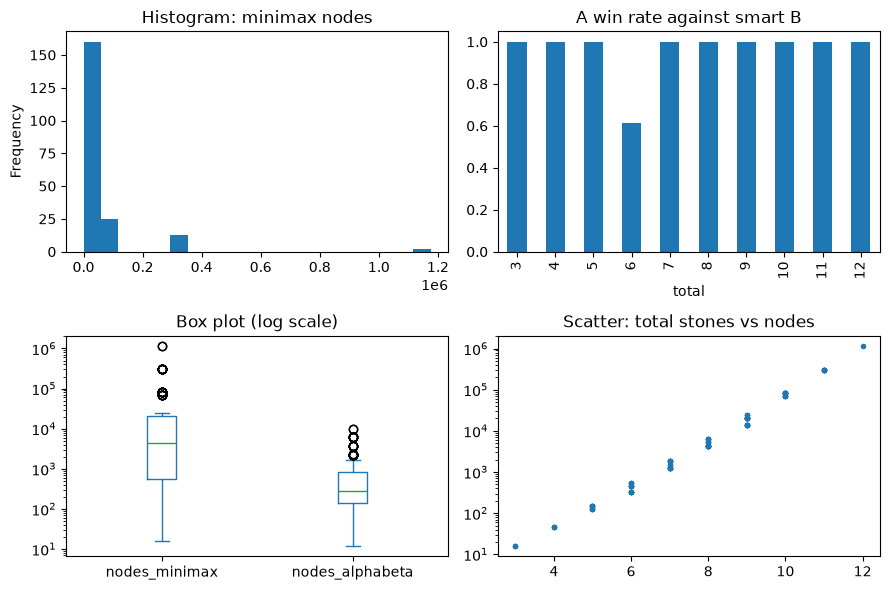

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
df["nodes_minimax"].plot(kind="hist", bins=20, ax=axes[0, 0], title="Histogram: minimax nodes")
df.assign(a_win=df["winner"].eq("A")).groupby("total")["a_win"].mean().plot(
    kind="bar", ax=axes[0, 1], title="A win rate against smart B"
)
df[["nodes_minimax", "nodes_alphabeta"]].plot(kind="box", logy=True, ax=axes[1, 0], title="Box plot (log scale)")
axes[1, 1].scatter(df["total"], df["nodes_minimax"], s=8)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Scatter: total stones vs nodes")
plt.tight_layout()
plt.show()

## Interpretation (write it yourself in README)
Use the pattern: **observation, reason, conclusion**. Example: *A wins from 88 percent of the starts (observation); most starts have nim_sum different from 0 (reason); so the first player has an advantage (conclusion).*

# Part 3: Motion output

## Cell 9: Animation of one game

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

rng = np.random.default_rng(1)
board, player = START, "A"
history = [(board, "start")]
while sum(board) > 0:
    old = board
    if player == "A":
        board = best_move(board, "A")
    else:
        options = moves(board)
        board = options[rng.integers(len(options))]
    i = [k for k in range(3) if board[k] != old[k]][0]
    history.append((board, f"{player} takes {old[i] - board[i]} from pile {i}"))
    player = "B" if player == "A" else "A"
winner = "B" if player == "A" else "A"

fig, ax = plt.subplots(figsize=(4, 3), dpi=70)

def draw(t):
    piles, text = history[min(t, len(history) - 1)]
    ax.clear()
    ax.bar(["pile 0", "pile 1", "pile 2"], piles, color=["#4f46e5", "#ec4899", "#f59e0b"])
    ax.set_ylim(0, max(START) + 1)
    ax.set_title(text + ("   winner: " + winner if t >= len(history) - 1 else ""), fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(history) + 3, interval=800)
plt.close(fig)
HTML(anim.to_jshtml())

## Challenges
Smart B too, 4 piles, other pile ranges, ordering by nim-sum, normal versus misere rule.

## Selected development: Smart B too (پیاده‌سازی حریف هوشمند برای بازیکن B)

در کد پایه، بازیکن A با Minimax/Alpha-Beta حرکت می‌کند، اما بازیکن B به‌صورت تصادفی حرکت می‌کند. در این توسعه، هر دو بازیکن از تابع `best_move` استفاده می‌کنند. این تابع با توجه به نوبت بازیکن، برای A مقدار بیشینه و برای B مقدار کمینه را انتخاب می‌کند؛ بنابراین B نیز با راهبرد بهینه بازی می‌کند.

برای مقایسه، ۲۰۰ وضعیت شروع یکسان را در دو حالت اجرا می‌کنیم:
1. A هوشمند در برابر B تصادفی (حالت پایه)
2. A هوشمند در برابر B هوشمند (توسعه انتخاب‌شده)


In [ ]:
def play_nim(piles, strategy_a="smart", strategy_b="random", rng=None):
    """Play one normal-play Nim game and return (winner, number_of_moves)."""
    if rng is None:
        rng = np.random.default_rng()

    board = tuple(int(x) for x in piles)
    player = "A"
    move_count = 0

    while sum(board) > 0:
        strategy = strategy_a if player == "A" else strategy_b

        if strategy == "smart":
            # best_move supports both MAX (A) and MIN (B).
            board = best_move(board, player)
        elif strategy == "random":
            options = moves(board)
            board = options[int(rng.integers(len(options)))]
        else:
            raise ValueError("strategy must be 'smart' or 'random'")

        move_count += 1

        if sum(board) == 0:
            return player, move_count

        player = "B" if player == "A" else "A"

    return ("B" if player == "A" else "A"), move_count


rng_starts = np.random.default_rng(2026)
rng_random = np.random.default_rng(2027)
comparison_rows = []

for game in range(200):
    start = tuple(int(x) for x in rng_starts.integers(1, 5, size=3))

    winner_random, moves_random = play_nim(
        start, strategy_a="smart", strategy_b="random", rng=rng_random
    )
    winner_both_smart, moves_both_smart = play_nim(
        start, strategy_a="smart", strategy_b="smart", rng=rng_random
    )

    comparison_rows.append({
        "p1": start[0],
        "p2": start[1],
        "p3": start[2],
        "nim_sum": start[0] ^ start[1] ^ start[2],
        "winner_smart_vs_random": winner_random,
        "moves_smart_vs_random": moves_random,
        "winner_smart_vs_smart": winner_both_smart,
        "moves_smart_vs_smart": moves_both_smart,
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.head())

print("A win rate: smart A vs random B:",
      round((comparison_df["winner_smart_vs_random"] == "A").mean() * 100, 1), "%")
print("A win rate: smart A vs smart B:",
      round((comparison_df["winner_smart_vs_smart"] == "A").mean() * 100, 1), "%")
print("B win rate: smart A vs smart B:",
      round((comparison_df["winner_smart_vs_smart"] == "B").mean() * 100, 1), "%")


In [ ]:
win_rates = pd.Series({
    "Smart A vs Random B": (comparison_df["winner_smart_vs_random"] == "A").mean() * 100,
    "Smart A vs Smart B": (comparison_df["winner_smart_vs_smart"] == "A").mean() * 100,
})
ax = win_rates.plot(kind="bar", figsize=(7, 4), ylim=(0, 100), rot=0,
                    title="A win rate under two opponent strategies")
ax.set_ylabel("A wins (%)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


### توضیح کوتاه توسعه و نتیجه

**تغییر کد:** در تابع `play_nim`، دیگر نوبت B به‌صورت تصادفی انتخاب نمی‌شود؛ اگر راهبرد B برابر `smart` باشد، همان تابع `best_move` با بازیکن جاری B فراخوانی می‌شود. تابع `best_move` برای B حرکت با کمترین مقدار Minimax را انتخاب می‌کند.

**نحوه عملکرد:** هر دو بازیکن در هر نوبت تمام حرکت‌های مجاز را با Alpha-Beta ارزیابی می‌کنند و حرکتی را انتخاب می‌کنند که نتیجه بازی را برای خودشان بهتر کند. در نتیجه، B نیز مانند A از بازی تصادفی خارج می‌شود.

پس از اجرای سلول‌ها، درصد برد A در دو حالت را از خروجی بخوانید و در گزارش خود با اشاره به این نکته تفسیر کنید که وقتی هر دو طرف بهینه بازی می‌کنند، نتیجه به وضعیت شروع بازی (از جمله `nim_sum`) وابسته است.
